# Hypothesis 1: Total turnover goes down on rainy days

**Author:** Julian · **Canvas:** block 2 (Q2b Weather, hypothesis 1)

**Purpose.** We test whether the bakery sells less on days with rain. If it does, the manager could bake less when rain is expected, and our model should use a rain feature.

**Definitions (decided by the team, see `DECISIONS.md`):**
- **Total turnover** = sum of product groups 1–5 (bread, rolls, croissants, confectionery, cakes) per day, only on days on which all five groups have a row. Seasonal bread (6) is left out of the total because it is only sold October–January.
- **Rainy day** = precipitation flag (decision D5): `Wettercode` 50–99 (drizzle, rain, snow, showers, thunderstorm) → 1; any other code or a missing code → 0.
- **Data:** training period only, 2013-07-01 – 2017-07-31, so that the validation year stays untouched. 2014-05-05 is excluded (decision D2). Days without any weather row are left out (we cannot know whether it rained).

**Approach.**
1. Naive comparison: average total turnover on rainy vs. dry days.
2. Check for *confounding*: is rain more common in some months, weekdays or years, which have different turnover anyway?
3. Fair comparison: a regression that compares rainy and dry days within the same month, weekday and year.
4. The same per product group.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf
from scipy import stats

BASE_URL = "https://raw.githubusercontent.com/opencampus-sh/intro-to-data-science-and-ml/main/data/bakery/"
TRAIN_START, TRAIN_END = "2013-07-01", "2017-07-31"
EXCLUDED_DAYS = ["2014-05-05"]  # decision D2
WEEKDAYS = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
GROUPS = {1: "Bread", 2: "Rolls", 3: "Croissants", 4: "Confectionery", 5: "Cakes", 6: "Seasonal bread"}

sales = pd.read_csv(BASE_URL + "umsatzdaten_gekuerzt.csv", parse_dates=["Datum"])
weather = pd.read_csv(BASE_URL + "wetter.csv", parse_dates=["Datum"])
print(sales.shape, weather.shape)

(9334, 4) (2601, 5)


## 1. Prepare the data

We keep the training period, remove the excluded day, and build the rain flag. Then we add up groups 1–5 per day and keep only days on which all five groups sold something.

In [2]:
sales = sales[sales.Datum.between(TRAIN_START, TRAIN_END) & ~sales.Datum.isin(pd.to_datetime(EXCLUDED_DAYS))]

weather["rain"] = weather.Wettercode.between(50, 99).astype(int)  # missing code -> 0 (D5)

main = sales[sales.Warengruppe <= 5]
daily = main.groupby("Datum").agg(total=("Umsatz", "sum"), n_groups=("Warengruppe", "nunique")).reset_index()
n_open_days = len(daily)
daily = daily[daily.n_groups == 5]
n_all_groups = len(daily)

daily = daily.merge(weather[["Datum", "rain"]], on="Datum", how="inner")
daily["month"] = daily.Datum.dt.month
daily["weekday"] = pd.Categorical(daily.Datum.dt.day_name(), categories=WEEKDAYS, ordered=True)
daily["year"] = daily.Datum.dt.year
daily["rain_label"] = daily.rain.map({0: "dry", 1: "rainy"})

print(f"open days in training period:          {n_open_days}")
print(f"... with all groups 1-5:               {n_all_groups}")
print(f"... and with a weather row (analysed): {len(daily)}")
print(f"rainy days: {daily.rain.sum()} ({daily.rain.mean():.1%})")

open days in training period:          1461
... with all groups 1-5:               1408
... and with a weather row (analysed): 1407
rainy days: 491 (34.9%)


In [3]:
# Checks for this notebook: one row per day, no missing values, period as intended
assert daily.Datum.is_unique
assert daily[["total", "rain", "month", "weekday", "year"]].notna().all().all()
assert daily.Datum.min() >= pd.Timestamp(TRAIN_START) and daily.Datum.max() <= pd.Timestamp(TRAIN_END)
assert not daily.Datum.isin(pd.to_datetime(EXCLUDED_DAYS)).any()
assert set(daily.rain.unique()) <= {0, 1}

## 2. Naive comparison: rainy vs. dry days

The bars show the average total turnover; the black lines are **95 % confidence intervals**: the range in which the true average plausibly lies, given how much single days vary.

             days    mean  ci_low  ci_high
rain_label                                
dry         916.0  1069.3  1051.5   1087.2
rainy       491.0  1023.8   998.3   1049.4

Difference rainy - dry: -45.5 (-4.3% of a dry day); Welch t-test p = 0.004


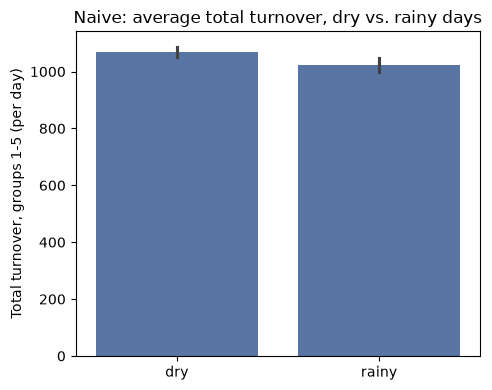

In [4]:
def mean_ci(x):
    m, se = x.mean(), x.std(ddof=1) / np.sqrt(len(x))
    h = se * stats.t.ppf(0.975, len(x) - 1)
    return pd.Series({"days": len(x), "mean": m, "ci_low": m - h, "ci_high": m + h})

naive = daily.groupby("rain_label").total.apply(mean_ci).unstack()
print(naive.round(1))

t = stats.ttest_ind(daily.total[daily.rain == 1], daily.total[daily.rain == 0], equal_var=False)
diff = naive.loc["rainy", "mean"] - naive.loc["dry", "mean"]
print(f"\nDifference rainy - dry: {diff:.1f} ({diff / naive.loc['dry', 'mean']:.1%} of a dry day); Welch t-test p = {t.pvalue:.3f}")

fig, ax = plt.subplots(figsize=(5, 4))
sns.barplot(data=daily, x="rain_label", y="total", order=["dry", "rainy"], errorbar=("ci", 95), color="#4c72b0", ax=ax)
ax.set(xlabel="", ylabel="Total turnover, groups 1-5 (per day)", title="Naive: average total turnover, dry vs. rainy days")
plt.tight_layout(); plt.show()

## 3. Is the naive comparison fair? Checking for confounding

Rain is not spread evenly. If rainy days fall mostly in months, weekdays or years with lower (or higher) turnover anyway, the naive difference partly measures *those* instead of rain. This is called **confounding**. We look at the share of rainy days and the average turnover per month, weekday and year.

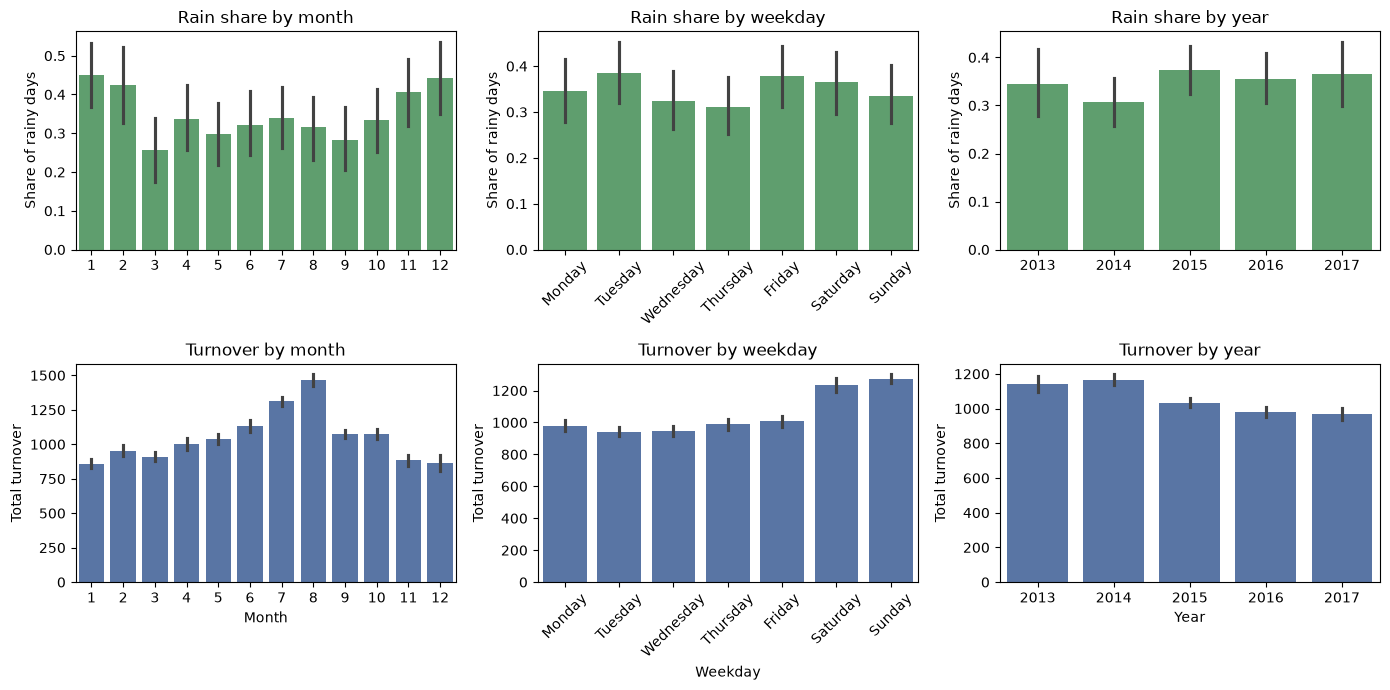

Correlation of monthly rain share with monthly mean turnover: -0.45
Rain share by month: {1: 0.45, 2: 0.42, 3: 0.26, 4: 0.34, 5: 0.3, 6: 0.32, 7: 0.34, 8: 0.32, 9: 0.28, 10: 0.33, 11: 0.41, 12: 0.44}
Rain share by year:  {2013: 0.35, 2014: 0.31, 2015: 0.37, 2016: 0.36, 2017: 0.37}


In [5]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for col, (key, label) in enumerate([("month", "Month"), ("weekday", "Weekday"), ("year", "Year")]):
    sns.barplot(data=daily, x=key, y="rain", errorbar=("ci", 95), color="#55a868", ax=axes[0, col])
    axes[0, col].set(ylabel="Share of rainy days", xlabel="", title=f"Rain share by {label.lower()}")
    sns.barplot(data=daily, x=key, y="total", errorbar=("ci", 95), color="#4c72b0", ax=axes[1, col])
    axes[1, col].set(ylabel="Total turnover", xlabel=label, title=f"Turnover by {label.lower()}")
for ax in axes[:, 1]:
    ax.tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()

by_month = daily.groupby("month")[["rain", "total"]].mean()
print("Correlation of monthly rain share with monthly mean turnover:", round(by_month.corr().iloc[0, 1], 2))
print("Rain share by month:", by_month.rain.round(2).to_dict())
print("Rain share by year: ", daily.groupby("year").rain.mean().round(2).to_dict())

## 4. Fair comparison: rain effect within the same month, weekday and year

We fit a linear regression: `total ~ rain + month + weekday + year`. Month, weekday and year enter as categories, so the rain coefficient compares rainy and dry days **that share the same month, weekday and year**. Year is included because `Wettercode` was reported less often in early years (fact sheet), so the rain flag itself changes over the years.

Neighbouring days are similar to each other, which makes ordinary standard errors too optimistic. We therefore use *HAC* standard errors (Newey-West, 7 days), which allow for that.

In [6]:
def rain_effect(df, y):
    model = smf.ols(f"{y} ~ rain + C(month) + C(weekday) + C(year)", data=df).fit(cov_type="HAC", cov_kwds={"maxlags": 7})
    coef, (lo, hi) = model.params["rain"], model.conf_int().loc["rain"]
    base = df.loc[df.rain == 0, y].mean()
    return pd.Series({"effect": coef, "ci_low": lo, "ci_high": hi, "p_value": model.pvalues["rain"],
                      "effect_pct": coef / base, "ci_low_pct": lo / base, "ci_high_pct": hi / base,
                      "days": len(df), "rainy_days": int(df.rain.sum())})

adjusted = rain_effect(daily, "total")
compare = pd.DataFrame({
    "naive": [diff, diff / naive.loc["dry", "mean"]],
    "adjusted (month, weekday, year)": [adjusted.effect, adjusted.effect_pct],
}, index=["difference rainy - dry", "as share of a dry day"])
print(compare.round(3))
print(f"\nAdjusted effect 95% CI: {adjusted.ci_low:.1f} to {adjusted.ci_high:.1f} "
      f"({adjusted.ci_low_pct:.1%} to {adjusted.ci_high_pct:.1%}); p = {adjusted.p_value:.4f}")

                         naive  adjusted (month, weekday, year)
difference rainy - dry -45.503                          -17.993
as share of a dry day   -0.043                           -0.017

Adjusted effect 95% CI: -40.3 to 4.3 (-3.8% to 0.4%); p = 0.1134


## 5. Per product group

The same regression for each group 1–5 separately (all training days on which the group sold). Seasonal bread (6) has too few days for this model and is shown only descriptively, within its season.

                 days  rainy_days  effect  effect_pct  ci_low_pct  ci_high_pct  p_value
Bread          1460.0       510.0  -2.892        -2.4        -5.4          0.7    0.126
Rolls          1460.0       510.0  -4.397        -1.1        -3.3          1.2    0.359
Croissants     1460.0       510.0  -3.822        -2.3        -5.3          0.8    0.142
Confectionery  1407.0       491.0  -0.435        -0.5        -3.9          2.9    0.777
Cakes          1460.0       510.0  -4.062        -1.4        -5.5          2.7    0.492


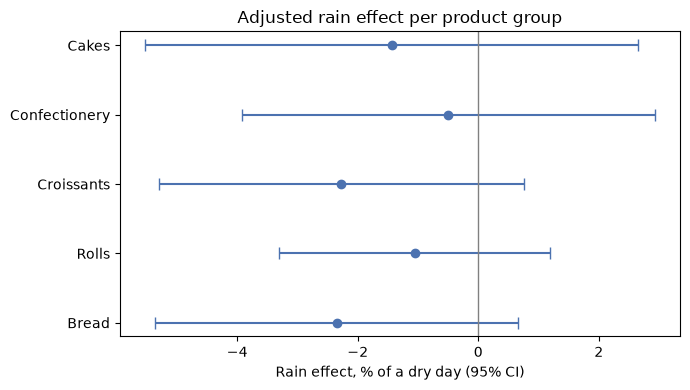


Seasonal bread (in season only), descriptive:
             days  mean  ci_low  ci_high
rain_label                              
dry         130.0  67.1    61.6     72.7
rainy       105.0  66.6    60.0     73.2


In [7]:
grp = sales.merge(weather[["Datum", "rain"]], on="Datum", how="inner")
grp["month"], grp["year"] = grp.Datum.dt.month, grp.Datum.dt.year
grp["weekday"] = pd.Categorical(grp.Datum.dt.day_name(), categories=WEEKDAYS, ordered=True)

per_group = pd.DataFrame({GROUPS[g]: rain_effect(grp[grp.Warengruppe == g], "Umsatz") for g in range(1, 6)}).T
show = per_group[["days", "rainy_days", "effect", "effect_pct", "ci_low_pct", "ci_high_pct", "p_value"]].copy()
show[["effect_pct", "ci_low_pct", "ci_high_pct"]] = (show[["effect_pct", "ci_low_pct", "ci_high_pct"]] * 100).round(1)
print(show.round(3).to_string())

fig, ax = plt.subplots(figsize=(7, 4))
y = np.arange(len(per_group))
ax.errorbar(per_group.effect_pct * 100, y,
            xerr=[(per_group.effect_pct - per_group.ci_low_pct) * 100, (per_group.ci_high_pct - per_group.effect_pct) * 100],
            fmt="o", color="#4c72b0", capsize=4)
ax.axvline(0, color="grey", lw=1)
ax.set_yticks(y, per_group.index)
ax.set(xlabel="Rain effect, % of a dry day (95% CI)", title="Adjusted rain effect per product group")
plt.tight_layout(); plt.show()

g6 = grp[grp.Warengruppe == 6].assign(rain_label=lambda d: d.rain.map({0: "dry", 1: "rainy"}))
print("\nSeasonal bread (in season only), descriptive:")
print(g6.groupby("rain_label").Umsatz.apply(mean_ci).unstack().round(1))

## 6. Conclusion

**Rain alone barely lowers turnover: most of the apparent drop on rainy days is a winter effect.**

- **Naive comparison:** on rainy days the bakery takes in 1,024 on average, on dry days 1,069: **−45.5 (−4.3 %)**, clearly beyond chance (p = 0.004).
- **Confounding:** rain is most frequent from November to February (41–45 % of days), and these are also the months with the lowest turnover (August, the peak month, averages about 1,465; January about 860). Monthly rain share and monthly turnover are negatively correlated (−0.45). So part of the naive difference measures *winter*, not *rain*.
- **Fair comparison** (same month, weekday and year): the rain effect shrinks to **−18 (−1.7 %)**, 95 % CI **−3.8 % to +0.4 %** (p = 0.11). The data are consistent with a small dip, but also with no effect at all.
- **Per product group:** all five point estimates are slightly negative (bread −2.4 %, croissants −2.3 %, cakes −1.4 %, rolls −1.1 %, confectionery −0.5 %), and every confidence interval includes 0. Seasonal bread shows no difference (67.1 dry vs. 66.6 rainy, in season).

**Verdict on hypothesis 1:** *not supported* as an effect that matters for planning. If rain lowers turnover at all, it is by about 2 % of a day; weekday (Sat/Sun ≈ +30 %) and season (Aug vs. Jan ≈ +70 %) matter far more.

**What this means for the model:** the rain flag can stay as a candidate feature, but we should not expect it to improve the forecast much. Month and weekday are the important features.

**Limits:**
- Rain is recorded as one flag per day: a short shower in the evening counts the same as a rainy morning, when most bread is bought. This blurs a possible effect towards zero.
- A missing `Wettercode` counts as "dry" (D5); some rainy days may be hidden among the dry ones, which also blurs the effect towards zero.
- We use *observed* weather; the manager only knows the forecast, so in real use the effect would be even weaker.
- Training period only (Jul 2013 – Jul 2017, 1,407 days, 491 rainy). The validation year was not looked at.